In [54]:
import pandas as pd
from matplotlib import pyplot as plt
import numpy as np
import seaborn as sns

In [4]:
df = pd.read_csv(r"C:\Users\Marcelo\Documents\proyrepasodipl\LearningProject\data\raw\bank-full.csv", sep=";")

In [5]:
df_limpio =df.copy()

In [7]:
df_limpio['aceptacion'] = df_limpio['y'].replace(['no','yes'],['0','1'])

In [10]:
df_limpio['aceptacion']=df_limpio['aceptacion'].astype(int)

In [11]:
df_limpio

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y,aceptacion
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes,1
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes,1
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes,1
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no,0


In [20]:
serie=df_limpio.groupby("job")["aceptacion"].mean().sort_values(ascending=True)*100

<Axes: ylabel='job'>

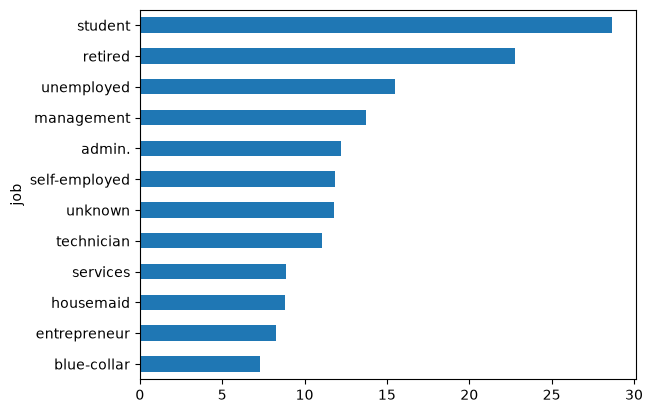

In [21]:
serie.plot(kind='barh')

In [25]:
glbl = df_limpio["aceptacion"].mean() * 100 

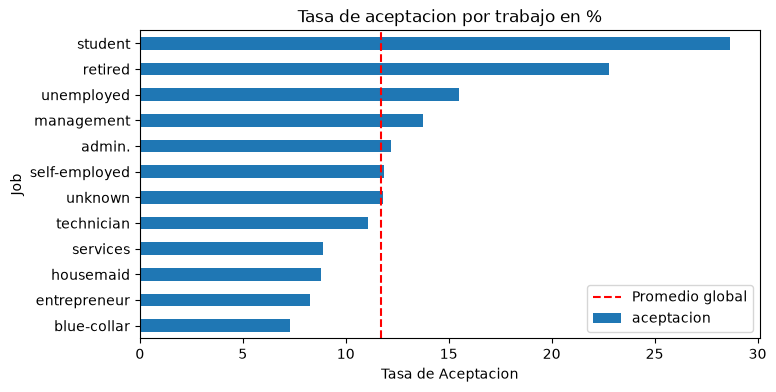

In [27]:
fig, ax1 = plt.subplots(figsize=(8, 4))
serie.plot(kind="barh", ax=ax1, rot=0)
ax1.axvline(x=glbl, color="red", linestyle="--", label="Promedio global")
ax1.legend()
ax1.set_ylabel("Job")
ax1.set_xlabel("Tasa de Aceptacion")
ax1.set_title("Tasa de aceptacion por trabajo en %")
plt.show()

In [28]:
df_limpio.groupby("job")["aceptacion"].agg(["mean", "size"])

,mean,size
job,,
admin.,0.122027,5171
blue-collar,0.072750,9732
entrepreneur,0.082717,1487
housemaid,0.087903,1240
management,0.137556,9458
retired,0.227915,2264
self-employed,0.118429,1579
services,0.088830,4154
student,0.286780,938


In [29]:
df_limpio_filtrado1 = df_limpio[df_limpio['job'].isin(["student","retired"])]

In [30]:
df_limpio_filtrado1

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y,aceptacion
8,58,retired,married,primary,no,121,yes,no,unknown,5,may,50,1,-1,0,unknown,no,0
15,51,retired,married,primary,no,229,yes,no,unknown,5,may,353,1,-1,0,unknown,no,0
18,60,retired,married,primary,no,60,yes,no,unknown,5,may,219,1,-1,0,unknown,no,0
24,40,retired,married,primary,no,0,yes,yes,unknown,5,may,181,1,-1,0,unknown,no,0
43,54,retired,married,secondary,no,529,yes,no,unknown,5,may,1492,1,-1,0,unknown,no,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45196,25,student,single,secondary,no,358,no,no,cellular,16,nov,330,1,-1,0,unknown,yes,1
45203,23,student,single,tertiary,no,113,no,no,cellular,17,nov,266,1,-1,0,unknown,yes,1
45204,73,retired,married,secondary,no,2850,no,no,cellular,17,nov,300,1,40,8,failure,yes,1
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes,1


In [34]:
df_limpio["rango"] = pd.cut(df_limpio["age"], bins=[ 0,30, 50, 100], labels=["<30", "30-50", ">50"])


In [35]:
res = df_limpio.groupby(["rango", "job"])["aceptacion"].agg(["mean", "size"])


In [37]:
res

mean  size
rango job                          
<30   admin.         0.148033   966
      blue-collar    0.111266  1438
      entrepreneur   0.088889   135
      housemaid      0.119403    67
      management     0.194514  1203
      retired        0.000000     4
      self-employed  0.209677   248
      services       0.111922   822
      student        0.305592   769
      technician     0.146194  1156
      unemployed     0.177340   203
      unknown        0.210526    19
30-50 admin.         0.111176  3427
      blue-collar    0.065941  6794
      entrepreneur   0.079767  1028
      housemaid      0.070809   692
      management     0.126890  6549
      retired        0.040541   148
      self-employed  0.099029  1030
      services       0.083934  2776
      student        0.201183   169
      technician     0.099175  5334
      unemployed     0.145455   825
      unknown        0.103896   154
>50   admin.         0.137532   778
      blue-collar    0.066667  1500
      entrepreneur   0.089506   324
      housemaid      0.108108   481
      management     0.138335  1706
      retired        0.241477  2112
      self-employed  0.109635   301
      services       0.079137   556
      technician     0.128275  1107
      unemployed     0.167273   275
      unknown        0.121739   115

In [36]:
res["mean"].unstack() * 100

job,admin.,blue-collar,entrepreneur,housemaid,management,retired,self-employed,services,student,technician,unemployed,unknown
rango,,,,,,,,,,,,
<30,14.803313,11.126565,8.888889,11.940299,19.451372,0.000000,20.967742,11.192214,30.559168,14.619377,17.733990,21.052632
30-50,11.117596,6.594054,7.976654,7.080925,12.688960,4.054054,9.902913,8.393372,20.118343,9.917510,14.545455,10.389610
>50,13.753213,6.666667,8.950617,10.810811,13.833529,24.147727,10.963455,7.913669,NaN,12.827462,16.727273,12.173913


In [38]:
df_limpio["grupo"] = df_limpio["job"].where(df_limpio["job"].isin(["student", "retired"]), "otros")


In [39]:
res1 = df_limpio.groupby(["rango", "grupo"])["aceptacion"].agg(["mean", "size"])


In [40]:
res1

mean   size
rango grupo                   
<30   otros    0.145437   6257
      retired  0.000000      4
      student  0.305592    769
30-50 otros    0.097557  28609
      retired  0.040541    148
      student  0.201183    169
>50   otros    0.112418   7143
      retired  0.241477   2112

Comparando dentro de cada rango de edad, student en menores de 30 acepta 30,5% frente a 14,5% de otros (769 llamadas), y retired en mayores de 50 acepta 24,1% frente a 11,2% (2.112 llamadas). El trabajo influye en la aceptación más allá de la edad. En 30-50, student también supera a otros (20% frente a 9,7%), pero con solo 169 llamadas, así que se toma con cautela. Es una asociación, no una causa.

### Decisión: `unknown` en `job`

- 288 filas (~0,6% del total). Tasa de aceptación global ≈ promedio general (~12%).
- Por tramo de edad la tasa varía (19 <30: ~21%; 30-50: 10,3%; >50: 12,1%), pero con muestras muy pequeñas por tramo, por lo que la diferencia no es concluyente.
- **Decisión:** mantener `unknown` como categoría propia. Eliminarlas aporta poco (volumen mínimo) y no hay evidencia de que sean ruido; el modelo puede usarlas si aportan señal.
- Pendiente (otro proyecto): revisar si `unknown` en `job` se concentra en algún canal o campaña.

In [41]:
df_limpio.groupby("education")["aceptacion"].agg(["mean", "size"])

,mean,size
education,,
primary,0.086265,6851
secondary,0.105594,23202
tertiary,0.150064,13301
unknown,0.135703,1857


In [42]:
df_limpio["aceptacion"].mean()

np.float64(0.11698480458295547)

### Decisión: `unknown` en `education`

- 1.857 filas (~4,1% del total). Tasa de aceptación: 13,6% (global: 11,7%).
- La educación tiene gradiente claro: primary 8,6% → secondary 10,6% → tertiary 15,0%. `unknown` queda entre secondary y tertiary, y se diferencia de secondary (~3 pts con n grandes), por lo que no se comporta como la categoría más frecuente.
- **Decisión:** mantener `unknown` como categoría propia. Imputar con la moda (`secondary`) distorsionaría su tasa real, y eliminarlas descartaría ~4% de datos sin evidencia de que sean ruido.
- Pendiente (otro proyecto): revisar si `unknown` en `education` se concentra en ciertos `job` o campañas.

In [44]:
#creando columna contactado antes

df_limpio['contactado_antes'] = [1 if x > 0 else 0 for x in df_limpio["pdays"]]

In [47]:
df_limpio['contactado_antes'].value_counts()

contactado_antes
0    36954
1     8257
Name: count, dtype: int64

In [48]:
df_limpio.groupby("contactado_antes")["aceptacion"].agg(["mean", "size"])

,mean,size
contactado_antes,,
0,0.091573,36954
1,0.230713,8257


### Feature: `contactado_antes`

- Se construye a partir de `pdays` (`pdays != -1`), porque `pdays=-1` significa "nunca contactado" sin ambigüedad (`poutcome=unknown` mezcla 36.954 no contactados con 5 contactados sin resultado registrado).
- Validación: 0 → 36.954 filas, 1 → 8.257 filas.
- Tasa de aceptación: 9,2% (no contactados) vs 23,1% (contactados antes), unas 2,5 veces más.
- El flag aporta señal fuerte. Es una asociación: el banco eligió a quién llamar, por lo que los grupos pueden diferir en otros aspectos.
- Pendiente (otro proyecto): revisar si la diferencia se mantiene al controlar por `poutcome=success`.

In [50]:
df_limpio["pdays"] = df_limpio["pdays"].replace(-1,np.nan)

In [51]:
df_limpio["pdays"].isna().sum()

np.int64(36954)

In [52]:
df_limpio["pdays"].mean()

np.float64(224.57769165556496)

### Decisión: `pdays` con `-1`

- `pdays=-1` es un código para "nunca contactado", no un número real, y distorsiona cualquier promedio (40 días con el -1 frente a ~225 sin él).
- **Decisión:** reemplazar `-1` por `NaN` y conservar la columna. Aporta información útil (hace cuánto fue el último contacto) para los 8.257 clientes contactados antes. La columna `contactado_antes` ya guarda si hubo contacto.
- Validación: 36.954 `NaN` y promedio de 224,6 días.
- Pendiente (fase de modelado): ~82% de la columna queda en `NaN`. Decidir si se imputa con un valor apoyándose en el flag, o si se usa un modelo que tolere `NaN` (p. ej. `HistGradientBoosting`).

In [53]:
serie=df_limpio.groupby("job")["aceptacion"].mean().sort_values(ascending=True)*100
tabla = serie.reset_index()   # columnas: "region" y "convierte"


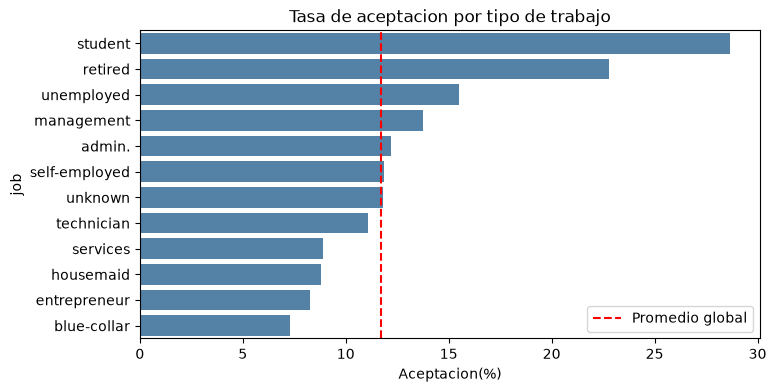

In [57]:
df_ej = tabla.sort_values("aceptacion", ascending=False)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=df_ej, x="aceptacion", y="job", color="steelblue", ax=ax)
ax.axvline(glbl, color="red", linestyle="--", label="Promedio global")
ax.set_xlabel("Aceptacion(%)")
ax.set_title("Tasa de aceptacion por tipo de trabajo")
ax.legend()
plt.show()